# Woche 6 – Supervised Learning: Prüfungs-Cheatsheet

Dieses Notebook ist ein ausführbares Nachschlagewerk für die prüfungsrelevanten Code-Muster aus Woche 6.

**Enthalten:** Datenaufteilung, lineare Regression, OLS, Regressionsbäume, Random Forest, Gradient Boosting, logistische Regression, Klassifikationsbäume, Klassifikations-Ensembles, Konfusionsmatrix, Precision/Recall, ROC/AUC, Kreuzvalidierung und Hyperparameter-Tuning.

**Nicht enthalten:** `06_kNN_Naive_Bayes_SVM` und `07_Clustering_PCA`.

## 0. Modellbewertung: wichtige Kennzahlen

Die Kennzahl wird immer auf bisher unbekannten Daten berechnet, zum Beispiel mit `y_test` (tatsächliche Werte) und `y_pred` (Vorhersagen). Für die Interpretation gilt: **Bei Fehlermaßen ist ein kleinerer Wert besser; bei Gütemaßen ist ein grösserer Wert besser.**

### Regression

Bei der Regression ist `y` eine kontinuierliche Zielgrösse, zum Beispiel ein Preis oder eine Temperatur. Mit dem Fehler `e_i = y_i - y_hat_i` gilt:

- **MSE (Mean Squared Error):** `MSE = (1/n) * Σ(y_i - y_hat_i)^2`; mittlerer quadratischer Fehler in quadrierten Zielgrösseneinheiten, wobei grosse Fehler besonders stark bestraft werden.
- **RMSE (Root Mean Squared Error):** `RMSE = sqrt(MSE)`; durchschnittliche Fehlergrösse ungefähr in den Einheiten der Zielgrösse, ebenfalls empfindlich gegenüber Ausreissern.
- **MAE (Mean Absolute Error):** `MAE = (1/n) * Σ|y_i - y_hat_i|`; durchschnittlicher absoluter Fehler in Zielgrösseneinheiten und robuster gegenüber Ausreissern als MSE/RMSE.
- **R² (Bestimmtheitsmass):** `R² = 1 - SSE/SST`; Anteil der Streuung von `y`, den das Modell erklärt, wobei `1` perfekte Erklärung, `0` ungefähr die Qualität einer konstanten Mittelwertvorhersage und ein negativer Wert eine schlechtere Vorhersage als diese Baseline bedeutet.

```python
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
```

### Klassifikation

Bei der binären Klassifikation wird zuerst eine **Konfusionsmatrix** erstellt:

```text
                 vorhergesagt 0   vorhergesagt 1
tatsächlich 0          TN              FP
tatsächlich 1          FN              TP
```

- **Accuracy (Trefferquote):** `(TP + TN) / (TP + TN + FP + FN)`; Anteil aller korrekt klassifizierten Fälle, aber bei unausgeglichenen Klassen oft irreführend.
- **Precision (Präzision):** `TP / (TP + FP)`; Anteil der tatsächlich positiven Fälle unter allen als positiv vorhergesagten Fällen.
- **Recall / Sensitivity / TPR:** `TP / (TP + FN)`; Anteil der tatsächlich positiven Fälle, die das Modell erkennt.
- **Specificity / TNR:** `TN / (TN + FP)`; Anteil der tatsächlich negativen Fälle, die korrekt als negativ erkannt werden.
- **FPR (False Positive Rate):** `FP / (FP + TN) = 1 - Specificity`; Anteil der tatsächlich negativen Fälle, die fälschlich positiv vorhergesagt werden.
- **F1-Score:** `2 * Precision * Recall / (Precision + Recall)`; harmonisches Mittel aus Precision und Recall, das beide Werte gemeinsam berücksichtigt.
- **ROC-Kurve:** stellt `TPR` gegen `FPR` für verschiedene Entscheidungsschwellenwerte dar; eine niedrigere oder höhere Schwelle verändert den Zielkonflikt zwischen gefundenen Positiven und Fehlalarmen.
- **AUC (Area Under the ROC Curve):** Fläche unter der ROC-Kurve; `0.5` entspricht ungefähr Zufall, `1.0` einer perfekten Trennung und je höher, desto besser kann das Modell positive Fälle rangieren.

Bei unausgeglichenen Klassen sollten insbesondere **Precision, Recall, F1 und AUC** zusätzlich zur Accuracy betrachtet werden; welche Kennzahl am wichtigsten ist, hängt von den Kosten für `FP` und `FN` ab. `predict()` liefert Klassenlabels, während `predict_proba()[:, 1]` Wahrscheinlichkeiten für die positive Klasse liefert und für ROC/AUC benötigt wird.


## 1. Setup und Datensatz

Der Datensatz enthält zwei typische Aufgaben:

- **Regression:** `price_chf` vorhersagen (kontinuierlicher Wert)
- **Klassifikation:** `service_needed` vorhersagen (Klasse 0 oder 1)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import (
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    RocCurveDisplay,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

DATA_PATH = "DS_HS2026_LNW_I_Examples/AP03/bicycle_data.csv"
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1200, 10)


,bicycle_id,age_years,mileage_km,equipment_level,is_ebike,brake_wear_pct,chain_wear_pct,months_since_service,price_chf,service_needed
0,B0001,7.9,9425,4,1,23.5,66.4,17,2984.87,0
1,B0002,4.7,5505,3,0,77.6,23.1,1,1355.88,0
2,B0003,8.7,13572,2,0,14.5,39.6,26,774.82,0
3,B0004,7.1,9903,4,1,60.3,18.2,4,3140.77,0
4,B0005,1.4,612,4,0,72.2,54.7,30,2064.10,0


## 2. Train-Test-Split

Der Testdatensatz darf nicht zum Training verwendet werden. `random_state` macht die Aufteilung reproduzierbar. Bei Klassifikation zusätzlich `stratify=y` verwenden, damit das Klassenverhältnis ungefähr erhalten bleibt.

In [ ]:
price_features = ["age_years", "mileage_km", "equipment_level", "is_ebike"]
X_price = df[price_features]
y_price = df["price_chf"]

X_train, X_test, y_train, y_test = train_test_split(
    X_price,
    y_price,
    test_size=0.20,  # legt fest, welcher Anteil für den Testdatensatz verwendet werden
    random_state=42, # bestimmt den Zufallsstartwert, damit die zufällige Aufteilung bei jeder Ausführung reproduzierbar bleibt.
)

service_features = [
    "age_years",
    "mileage_km",
    "brake_wear_pct",
    "chain_wear_pct",
    "months_since_service",
]
X_service = df[service_features]
y_service = df["service_needed"]

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_service,
    y_service,
    test_size=0.20,
    random_state=42,
    stratify=y_service,
)

## 3. Regressionsmodelle

### 3.1 Lineare Regression

Modell: `y_hat = beta_0 + beta_1*x_1 + ... + beta_p*x_p`.

Wichtige Kennzahlen:

- **R²:** Anteil der erklärten Varianz; höher ist besser.
- **MAE:** durchschnittlicher absoluter Fehler in Zielgrösseneinheiten.
- **RMSE:** bestraft grosse Fehler stärker als MAE; tiefer ist besser.

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)  # trainiert das lineare Modell

y_pred = linear_model.predict(X_test) #verwendet das trainierte lineare Modell, um für die Testdaten X_test die vorhergesagten Zielwerte zu berechnen
rmse = np.sqrt(mean_squared_error(y_test, y_pred)) # y_test = Testdaten, y_pred = Trainierte Daten

print("Intercept:", linear_model.intercept_)
print(pd.Series(linear_model.coef_, index=X_train.columns, name="coefficient"))
print("R²:", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE:", round(rmse, 2))

Intercept: 1318.022902237437
age_years           -99.986274
mileage_km           -0.026533
equipment_level     215.723846
is_ebike           1692.605202
Name: coefficient, dtype: float64
R²: 0.965
MAE: 145.94
RMSE: 181.11


### Elemente mit dessen Index finden

In [ ]:
X_train.iloc[640]

### 3.2 OLS mit `statsmodels`

`statsmodels` liefert zusätzlich statistische Kennzahlen wie Standardfehler, t-Werte und p-Werte. Für den Achsenabschnitt muss mit `sm.add_constant()` eine Konstante ergänzt werden.

In [4]:
import statsmodels.api as sm

X_train_ols = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_ols).fit()
print(ols_model.summary())

# Vorhersage auf neuen Daten: dieselbe Konstante ergänzen
X_test_ols = sm.add_constant(X_test, has_constant="add")
y_pred_ols = ols_model.predict(X_test_ols)
print("Test-R²:", round(r2_score(y_test, y_pred_ols), 3))

                            OLS Regression Results                            
Dep. Variable:              price_chf   R-squared:                       0.966
Model:                            OLS   Adj. R-squared:                  0.966
Method:                 Least Squares   F-statistic:                     6792.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:14:55   Log-Likelihood:                -6323.7
No. Observations:                 960   AIC:                         1.266e+04
Df Residuals:                     955   BIC:                         1.268e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const            1318.0229     17.819     

### 3.3 Cross-Validation für Regression

Kreuzvalidierung bewertet ein Modell auf mehreren Trainings-/Validierungsaufteilungen. Der Testdatensatz bleibt bis zur Schlussbewertung unberührt.

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2 = cross_val_score(LinearRegression(), X_price, y_price, cv=cv, scoring="r2")
print("R² je Fold:", np.round(cv_r2, 3))
print("Mittleres R²:", round(cv_r2.mean(), 3))

R² je Fold: [0.965 0.968 0.965 0.969 0.959]
Mittleres R²: 0.965


## 4. Regressionsbäume

Ein Baum teilt den Merkmalsraum über Regeln wie `mileage_km <= Schwellenwert`. Bei Regression ist der Blattwert typischerweise der Mittelwert der Trainingswerte im Blatt.

R²: 0.911
RMSE: 287.13


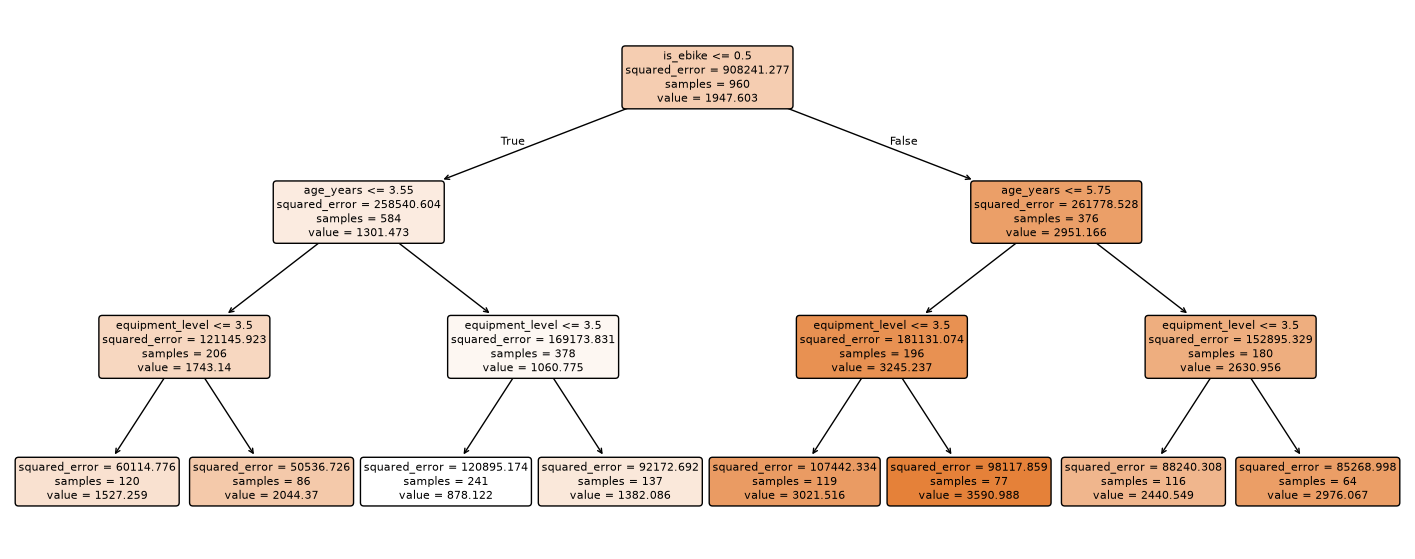

In [6]:
reg_tree = DecisionTreeRegressor(max_depth=3, random_state=42)
reg_tree.fit(X_train, y_train)
y_pred_tree = reg_tree.predict(X_test)

print("R²:", round(r2_score(y_test, y_pred_tree), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_tree)), 2))

plt.figure(figsize=(18, 7))
plot_tree(reg_tree, feature_names=X_train.columns, filled=True, rounded=True, fontsize=8)
plt.show()

### 4.1 Overfitting und Pruning

- Kleine `max_depth` / grosse `min_samples_leaf`: einfacheres Modell, weniger Varianz.
- Grosse `max_depth` / kleine Blätter: komplexeres Modell, Risiko von Overfitting.
- Hyperparameter auf Validierungsdaten oder per Cross-Validation wählen.

In [7]:
for depth in [1, 2, 3, 5, 10, None]:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    print(depth, round(r2_score(y_test, model.predict(X_test)), 3))

1 0.744
2 0.818
3 0.911
5 0.949
10 0.926
None 0.925


## 5. Ensembles für Regression

### 5.1 Random Forest

Viele Bäume werden auf Bootstrap-Stichproben trainiert. Die Vorhersage ist der Mittelwert der Einzelbäume. `feature_importances_` zeigt die relative Bedeutung der Merkmale.

R²: 0.957
RMSE: 198.98


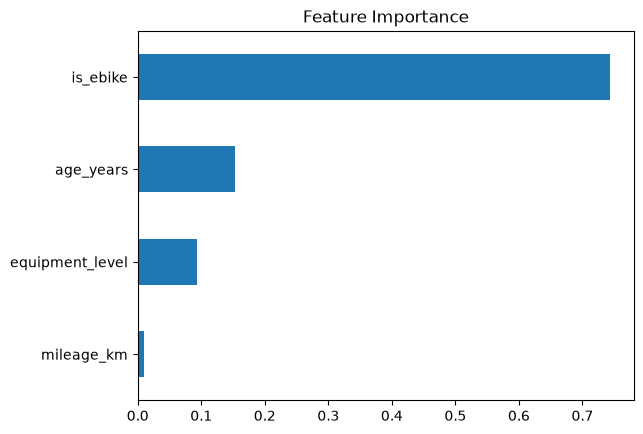

In [8]:
reg_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42,
)
reg_rf.fit(X_train, y_train)
y_pred_rf = reg_rf.predict(X_test)

print("R²:", round(r2_score(y_test, y_pred_rf), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2))

feature_importance = pd.Series(
    reg_rf.feature_importances_, index=X_train.columns
).sort_values()
feature_importance.plot(kind="barh", title="Feature Importance")
plt.show()

### 5.2 Gradient Boosting

Beim Boosting werden kleine Bäume nacheinander trainiert. Jeder neue Baum lernt aus den bisherigen Fehlern. Wichtige Hyperparameter sind `n_estimators`, `learning_rate` und `max_depth`.

In [9]:
reg_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42,
)
reg_gb.fit(X_train, y_train)
y_pred_gb = reg_gb.predict(X_test)
print("R²:", round(r2_score(y_test, y_pred_gb), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_gb)), 2))

R²: 0.957
RMSE: 201.02


## 6. Klassifikation

### 6.1 Logistische Regression

Die logistische Regression gibt eine Wahrscheinlichkeit für die positive Klasse zurück. Ein Schwellenwert, standardmässig `0.5`, wandelt diese Wahrscheinlichkeit in eine Klasse um. Wegen unterschiedlicher Skalen ist eine Pipeline mit `StandardScaler` sinnvoll.

In [10]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
logistic_model.fit(X_train_class, y_train_class)

class_pred = logistic_model.predict(X_test_class)
class_proba = logistic_model.predict_proba(X_test_class)[:, 1]

print("Accuracy:", round(accuracy_score(y_test_class, class_pred), 3))
print("Precision:", round(precision_score(y_test_class, class_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test_class, class_pred, zero_division=0), 3))
print(classification_report(y_test_class, class_pred, zero_division=0))

Accuracy: 0.921
Precision: 0.87
Recall: 0.797
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       181
           1       0.87      0.80      0.83        59

    accuracy                           0.92       240
   macro avg       0.90      0.88      0.89       240
weighted avg       0.92      0.92      0.92       240



### 6.2 Klassifikationsbaum

Der Klassifikationsbaum wählt Splits, die die Klassen möglichst stark trennen. Häufiges Unreinheitsmass ist der Gini-Index.

Accuracy: 0.879
AUC: 0.905


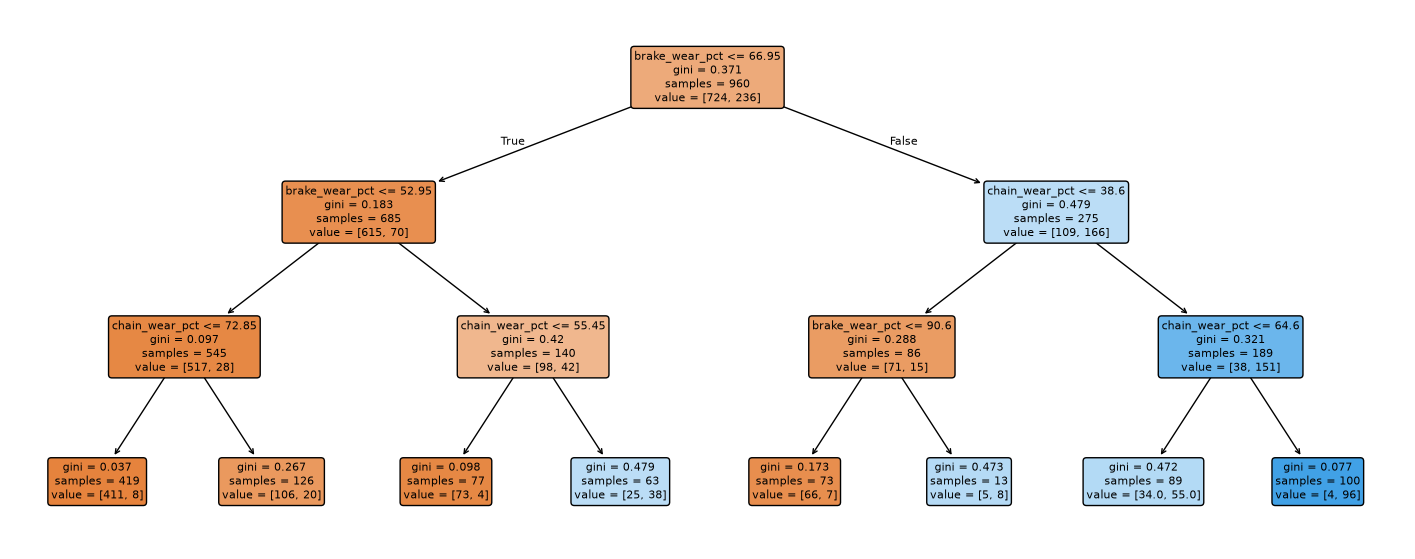

In [11]:
clf_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
clf_tree.fit(X_train_class, y_train_class)

clf_pred = clf_tree.predict(X_test_class)
clf_proba = clf_tree.predict_proba(X_test_class)[:, 1]
print("Accuracy:", round(accuracy_score(y_test_class, clf_pred), 3))
print("AUC:", round(roc_auc_score(y_test_class, clf_proba), 3))

plt.figure(figsize=(18, 7))
plot_tree(clf_tree, feature_names=X_train_class.columns, filled=True, rounded=True, fontsize=8)
plt.show()

### 6.3 Random Forest und Gradient Boosting für Klassifikation

In [12]:
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
)
rf_classifier.fit(X_train_class, y_train_class)
rf_pred = rf_classifier.predict(X_test_class)
rf_proba = rf_classifier.predict_proba(X_test_class)[:, 1]

print("Random Forest Accuracy:", round(accuracy_score(y_test_class, rf_pred), 3))
print("Random Forest AUC:", round(roc_auc_score(y_test_class, rf_proba), 3))

gb_classifier = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42,
)
gb_classifier.fit(X_train_class, y_train_class)
gb_proba = gb_classifier.predict_proba(X_test_class)[:, 1]
print("Gradient Boosting AUC:", round(roc_auc_score(y_test_class, gb_proba), 3))

Random Forest Accuracy: 0.908
Random Forest AUC: 0.948


Gradient Boosting AUC: 0.942


## 7. Klassifikationsmetriken

Bei `confusion_matrix` gilt für binäre Klassifikation:

```text
                 vorhergesagt 0   vorhergesagt 1
tatsächlich 0          TN              FP
tatsächlich 1          FN              TP
```

- **Accuracy** = `(TP + TN) / alle`
- **Precision** = `TP / (TP + FP)`
- **Recall / TPR** = `TP / (TP + FN)`
- **F1** = harmonisches Mittel aus Precision und Recall
- **Specificity / TNR** = `TN / (TN + FP)`

Bei unausgeglichenen Klassen ist Accuracy allein oft irreführend.

[[167  14]
 [ 15  44]]


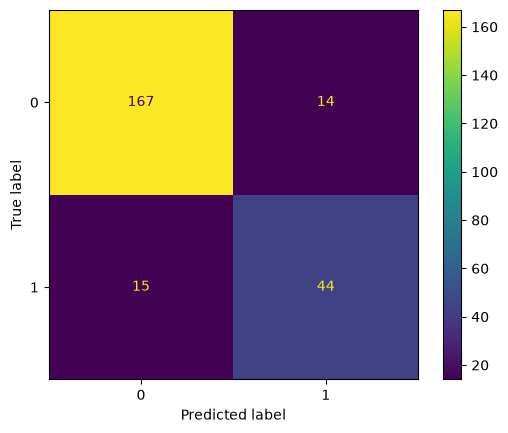

0.3 precision= 0.759 recall= 0.746
0.5 precision= 0.759 recall= 0.746
0.7 precision= 0.957 recall= 0.373


In [13]:
cm = confusion_matrix(y_test_class, clf_pred)
print(cm)
ConfusionMatrixDisplay.from_predictions(y_test_class, clf_pred)
plt.show()

# Schwellenwert bewusst verändern
for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = (clf_proba >= threshold).astype(int)
    print(
        threshold,
        "precision=", round(precision_score(y_test_class, threshold_pred, zero_division=0), 3),
        "recall=", round(recall_score(y_test_class, threshold_pred, zero_division=0), 3),
    )

## 8. ROC-Kurve und AUC

Die ROC-Kurve zeigt `TPR` gegen `FPR` für viele Schwellenwerte. **AUC = 0.5** entspricht ungefähr Zufall, **AUC = 1.0** perfekter Trennung. Für die ROC-Kurve Wahrscheinlichkeiten, nicht Klassenlabels, verwenden.

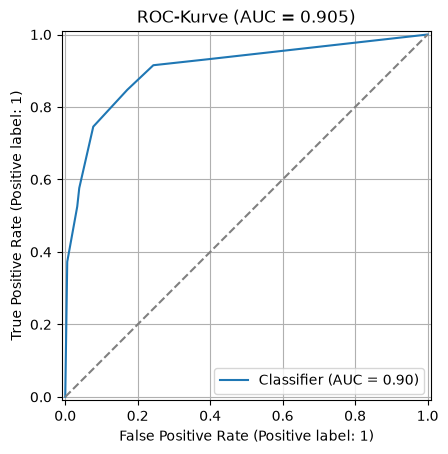

AUC: 0.905


In [14]:
roc_display = RocCurveDisplay.from_predictions(y_test_class, clf_proba)
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.title(f"ROC-Kurve (AUC = {roc_display.roc_auc:.3f})")
plt.grid()
plt.show()
print("AUC:", round(roc_auc_score(y_test_class, clf_proba), 3))

## 9. Kreuzvalidierung und Hyperparameter-Tuning

Für Klassifikation `StratifiedKFold` verwenden. Bei `GridSearchCV` wird der beste Parameter anhand der Cross-Validation gewählt. Erst danach das beste Modell einmal auf dem Testdatensatz bewerten.

In [15]:
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accuracy = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_service,
    y_service,
    cv=stratified_cv,
    scoring="accuracy",
)
print("CV Accuracy:", np.round(cv_accuracy, 3))
print("Mittelwert:", round(cv_accuracy.mean(), 3))

param_grid = {
    "max_depth": [2, 3, 5, None],
    "min_samples_leaf": [1, 5, 10],
}
search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=stratified_cv,
    scoring="roc_auc",
)
search.fit(X_train_class, y_train_class)
print("Beste Parameter:", search.best_params_)
print("Bestes CV-AUC:", round(search.best_score_, 3))
print("Test-AUC:", round(roc_auc_score(y_test_class, search.predict_proba(X_test_class)[:, 1]), 3))

CV Accuracy: [0.879 0.888 0.9   0.896 0.904]
Mittelwert: 0.893
Beste Parameter: {'max_depth': None, 'min_samples_leaf': 10}
Bestes CV-AUC: 0.897
Test-AUC: 0.905


## 10. Prüfungs-Checkliste

1. Ist die Zielgrösse kontinuierlich (**Regression**) oder kategorisch (**Klassifikation**)?
2. Sind `X` und `y` korrekt definiert?
3. Wurde vor dem Training ein Train-Test-Split durchgeführt?
4. Bei Klassifikation: `stratify=y` verwenden.
5. Skalierung nur dort einsetzen, wo sie nötig ist; für lineare/logistische Modelle oft sinnvoll.
6. Bei Regression R², MAE und RMSE unterscheiden.
7. Bei Klassifikation Confusion Matrix, Precision, Recall, F1 und AUC passend zur Fragestellung interpretieren.
8. Für ROC/AUC `predict_proba()` verwenden.
9. Komplexität von Bäumen mit `max_depth` und `min_samples_leaf` kontrollieren.
10. Hyperparameter mit Cross-Validation wählen und den Testdatensatz erst am Schluss verwenden.